# BAIR world model — 3. Evaluation and first report draft

Compare persistence, single-step Model A, and multi-step Model B at horizons 1–10 using the same held-out clips, initial three observed frames, and action sequence. After initialization, learned models receive only their own predicted frames. The persistence baseline repeats the final **observed** frame for every horizon.

This notebook computes per-clip endpoint MSE, PSNR, SSIM, and error within ground-truth changing pixels; plots error growth and prediction grids; and checks the proposal's two 10% improvement targets. The report section below now includes the measured results from the completed training run and 256-clip test evaluation. Freeze model choices before running final test evaluation.

In [1]:
from pathlib import Path
import json, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repository root or its notebooks/ directory.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "bair_hf_aux1_v1"
ARTIFACTS = ROOT / "artifacts" / "bair_hf_aux1_v1"
SEED = 4620
random.seed(SEED)
np.random.seed(SEED)

In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE, "| PyTorch:", torch.__version__)
if not (DATA / "manifest.csv").exists():
    raise FileNotFoundError("Run notebook 01 on real BAIR data before continuing.")
manifest = pd.read_csv(DATA / "manifest.csv")
metadata = json.loads((DATA / "metadata.json").read_text())
MANIFEST_HASH = hashlib.sha256((DATA / "manifest.csv").read_bytes()).hexdigest()
assert MANIFEST_HASH == metadata["manifest_sha256"]
with np.load(DATA / "action_stats.npz", allow_pickle=False) as stats:
    ACTION_MEAN, ACTION_STD = stats["mean"].copy(), stats["std"].copy()
CONTEXT, ACTION_DIM = 3, 4

Device: mps | PyTorch: 2.9.1


In [3]:
class BAIRWindows(Dataset):
    """All valid windows for training; one fixed start per clip for evaluation."""
    def __init__(self, split, horizon, all_windows=False):
        self.horizon = horizon
        self.items = []
        rows = manifest[manifest.split.eq(split)].sort_values("clip_id")
        for row in rows.itertuples():
            count = int(row.frames) - CONTEXT - horizon + 1
            if count < 1:
                raise ValueError(f"Clip {row.clip_id} too short for horizon {horizon}")
            for start in (range(count) if all_windows else [0]):
                self.items.append((row.path, start, row.clip_id))
        if not self.items:
            raise ValueError(f"No {split} windows. Check the manifest.")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, start, clip_id = self.items[index]
        with np.load(DATA / path, allow_pickle=False) as clip:
            frames = clip["frames"][start:start + CONTEXT + self.horizon].copy()
            # Last observed frame is at start+2; a[start+2] predicts frame[start+3].
            a0 = start + CONTEXT - 1
            actions = clip["actions"][a0:a0 + self.horizon].copy()
        frames = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255.0
        actions = torch.from_numpy((actions - ACTION_MEAN) / ACTION_STD)
        assert len(actions) == self.horizon
        return {"context": frames[:CONTEXT], "actions": actions,
                "target": frames[CONTEXT:], "clip_id": clip_id}

def make_loader(split, horizon, batch_size, train=False, seed=SEED):
    return DataLoader(BAIRWindows(split, horizon, all_windows=train),
                      batch_size=batch_size, shuffle=train, num_workers=0,
                      generator=torch.Generator().manual_seed(seed),
                      pin_memory=DEVICE.type == "cuda")

In [4]:
class ActionVideoModel(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.width = width
        self.encoder = nn.Sequential(
            nn.Conv2d(9, width, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(width, width * 2, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(width * 2, width * 4, 4, 2, 1), nn.ReLU())
        self.action_encoder = nn.Sequential(nn.Linear(ACTION_DIM, width), nn.ReLU())
        self.fuse = nn.Sequential(nn.Conv2d(width * 5, width * 4, 3, padding=1), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(width * 4, width * 2, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(width * 2, width, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(width, 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, context, action):
        b, t, c, h, w = context.shape
        assert (t, c, h, w) == (3, 3, 64, 64)
        visual = self.encoder(context.reshape(b, t * c, h, w))
        action_map = self.action_encoder(action)[:, :, None, None]
        action_map = action_map.expand(-1, -1, visual.shape[-2], visual.shape[-1])
        return self.decoder(self.fuse(torch.cat([visual, action_map], dim=1)))

def rollout(model, context, actions):
    history, predictions = context, []
    for step in range(actions.shape[1]):
        prediction = model(history, actions[:, step])
        predictions.append(prediction)
        # Preserve the graph: multi-step training backpropagates through predictions.
        history = torch.cat([history[:, 1:], prediction[:, None]], dim=1)
    return torch.stack(predictions, dim=1)

In [6]:
# EDIT: paste the exact run directory printed by notebook 02.
RUN = ARTIFACTS / "run_20261117T163624_197610Z"
SPLIT = "val"        # Use val for diagnosis. Set to "test" only after freezing choices.
HORIZONS = list(range(1, 11))
BATCH_SIZE = 32
MOTION_THRESHOLD = 10 / 255  # Mean absolute RGB difference from preceding true frame.
assert SPLIT in {"val", "test"}
if not (RUN / "config.json").exists():
    raise FileNotFoundError("Set RUN to a completed training run from notebook 02.")
config = json.loads((RUN / "config.json").read_text())
assert config["manifest_sha256"] == MANIFEST_HASH, "Training and evaluation manifests differ."
assert config["camera"] == metadata["camera"]
EVAL_DIR = RUN / f"evaluation_{SPLIT}"
EVAL_DIR.mkdir(exist_ok=True)

models = {}
for name in ["model_a_single_step", "model_b_multi_step"]:
    checkpoint = torch.load(RUN / f"{name}_best.pt", map_location="cpu", weights_only=True)
    assert checkpoint["config"]["manifest_sha256"] == MANIFEST_HASH
    assert np.allclose(checkpoint["action_mean"], ACTION_MEAN)
    assert np.allclose(checkpoint["action_std"], ACTION_STD)
    model = ActionVideoModel(checkpoint["config"]["width"]).to(DEVICE)
    model.load_state_dict(checkpoint["model_state"])
    models[name] = model.eval()
loader = make_loader(SPLIT, max(HORIZONS), BATCH_SIZE)
print(f"Evaluating {len(loader.dataset)} {SPLIT} clips.")

Evaluating 100 val clips.


## Metrics and aggregation

All frames are RGB floats in `[0,1]`. MSE is averaged over channels and pixels. Per-clip PSNR is `−10 log10(MSE)`; exact matches have infinite PSNR. SSIM uses scikit-image's 7×7 uniform window, RGB channel averaging, and `data_range=1`. Report these settings because SSIM implementations vary.

The motion mask uses only consecutive **ground-truth** frames to identify changing pixels. It is a diagnostic metric, not object tracking. Empty masks receive a missing value, and their counts are reported. Aggregate each metric equally across clips at each horizon. MSE and PSNR measure related pixel errors and are not independent evidence of perceptual realism.

In [7]:
from skimage.metrics import structural_similarity

def score_clip(pred, target, context):
    # Shapes: pred/target [H,C,Y,X], context [3,C,Y,X].
    previous_truth = np.concatenate([context[-1:], target[:-1]], axis=0)
    moving = np.abs(target - previous_truth).mean(axis=1) > MOTION_THRESHOLD
    rows = []
    for k in range(len(target)):
        error = (pred[k] - target[k])**2
        mse = float(error.mean())
        motion_pixels = int(moving[k].sum())
        rows.append(dict(
            horizon=k + 1, mse=mse,
            psnr=float(-10 * np.log10(mse)) if mse > 0 else float("inf"),
            ssim=float(structural_similarity(
                target[k].transpose(1, 2, 0), pred[k].transpose(1, 2, 0),
                channel_axis=-1, data_range=1.0, win_size=7, gaussian_weights=False)),
            motion_mse=float(error.mean(axis=0)[moving[k]].mean()) if motion_pixels else np.nan,
            motion_pixels=motion_pixels))
    return rows

records = []
with torch.no_grad():
    for batch in loader:
        context, actions = batch["context"].to(DEVICE), batch["actions"].to(DEVICE)
        predictions = {"persistence": context[:, -1:].expand(-1, max(HORIZONS), -1, -1, -1).cpu().numpy()}
        for name, model in models.items():
            predictions[name] = rollout(model, context, actions).cpu().numpy()
        for i, clip_id in enumerate(batch["clip_id"]):
            for name, pred in predictions.items():
                for row in score_clip(pred[i], batch["target"][i].numpy(), batch["context"][i].numpy()):
                    records.append(dict(clip_id=clip_id, model=name, split=SPLIT, **row))
scores = pd.DataFrame(records)
scores.to_csv(EVAL_DIR / "per_clip_metrics.csv", index=False)
summary = scores.groupby(["model", "horizon"]).agg(
    clips=("mse", "size"), mse=("mse", "mean"), psnr=("psnr", "mean"),
    ssim=("ssim", "mean"), motion_mse=("motion_mse", "mean"),
    clips_with_motion=("motion_mse", "count")).reset_index()
summary.to_csv(EVAL_DIR / "summary_metrics.csv", index=False)
display(summary[summary.horizon.isin([1, 5, 10])].round(6))
(EVAL_DIR / "evaluation_config.json").write_text(json.dumps(dict(
    split=SPLIT, horizons=HORIZONS, motion_threshold=MOTION_THRESHOLD,
    manifest_sha256=MANIFEST_HASH, window_start=0, context=3,
    ssim="skimage; win_size=7; gaussian_weights=False; data_range=1; channel_axis=-1"
), indent=2))

,model,horizon,clips,mse,psnr,ssim,motion_mse,clips_with_motion
0,model_a_single_step,1,100,0.006353,22.143630,0.816057,0.026599,100
4,model_a_single_step,5,100,0.013751,18.775999,0.674726,0.050230,98
9,model_a_single_step,10,100,0.023991,16.470234,0.555578,0.059892,100
10,model_b_multi_step,1,100,0.006292,22.242175,0.830008,0.027181,100
14,model_b_multi_step,5,100,0.008683,20.889529,0.782348,0.039082,98
19,model_b_multi_step,10,100,0.013005,19.261836,0.716226,0.042170,100
20,persistence,1,100,0.003294,27.157323,0.948850,0.043691,100
24,persistence,5,100,0.017884,18.576441,0.837461,0.098550,98
29,persistence,10,100,0.023050,17.527033,0.801269,0.091048,100


367

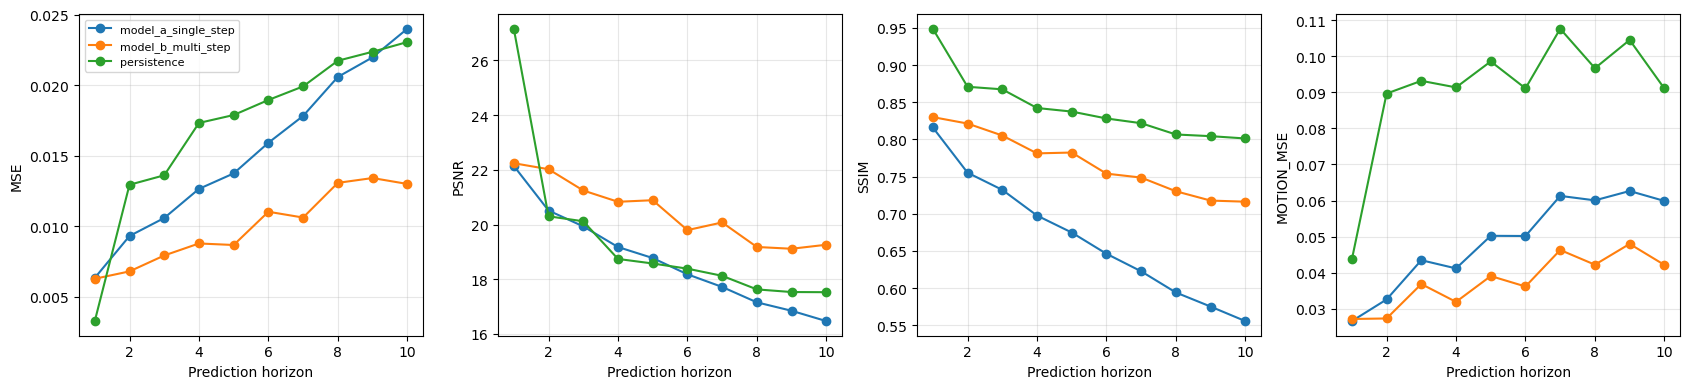

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for name, group in summary.groupby("model"):
    for ax, metric in zip(axes, ["mse", "psnr", "ssim", "motion_mse"]):
        ax.plot(group.horizon, group[metric], marker="o", label=name)
        ax.set(xlabel="Prediction horizon", ylabel=metric.upper())
        ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(EVAL_DIR / "metrics_by_horizon.png", dpi=160, bbox_inches="tight")
plt.show()

## Paired comparisons and the proposal's targets

Target 1: Model B reduces MSE by at least 10% against persistence at horizon 5. Also report Model A against the same baseline. Target 2: Model B reduces MSE by at least 10% against Model A at horizon 10. These are goals, not assumed outcomes.

Bootstrap whole paired clips, preserving each comparison's shared evaluation examples. Intervals quantify clip sampling uncertainty conditional on this trained run; they do not include variation across training seeds. No independence assumption is made between horizons.

In [9]:
def paired_comparison(reference, candidate, horizon, repetitions=2000):
    wide = scores[scores.horizon.eq(horizon)].pivot(index="clip_id", columns="model", values="mse")
    pair = wide[[reference, candidate]].dropna().to_numpy()
    denominator = pair[:, 0].mean()
    if denominator <= 0:
        raise ValueError("Relative improvement is undefined when reference MSE is zero.")
    improvement = 100 * (1 - pair[:, 1].mean() / denominator)
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(repetitions):
        sample = pair[rng.integers(0, len(pair), size=len(pair))]
        if sample[:, 0].mean() > 0:
            boot.append(100 * (1 - sample[:, 1].mean() / sample[:, 0].mean()))
    low, high = np.percentile(boot, [2.5, 97.5])
    return dict(reference=reference, candidate=candidate, horizon=horizon,
                improvement_percent=improvement, ci_low=low, ci_high=high,
                point_estimate_meets_10_percent=bool(improvement >= 10), clips=len(pair))

comparisons = pd.DataFrame([
    paired_comparison("persistence", "model_a_single_step", 5),
    paired_comparison("persistence", "model_b_multi_step", 5),
    paired_comparison("model_a_single_step", "model_b_multi_step", 10)])
comparisons.to_csv(EVAL_DIR / "paired_comparisons.csv", index=False)
display(comparisons.round(3))

,reference,candidate,horizon,improvement_percent,ci_low,ci_high,point_estimate_meets_10_percent,clips
0,persistence,model_a_single_step,5,23.109,12.238,32.126,True,100
1,persistence,model_b_multi_step,5,51.450,45.150,56.367,True,100
2,model_a_single_step,model_b_multi_step,10,45.791,41.504,49.861,True,100


## Visual diagnostics

Show the same first evaluation clip for every model, selected by clip ID before inspecting performance. This prevents cherry-picking. Inspect arm and object motion, contact events, blur, and drift. A good full-frame score can coexist with poor object dynamics because the background dominates the image.

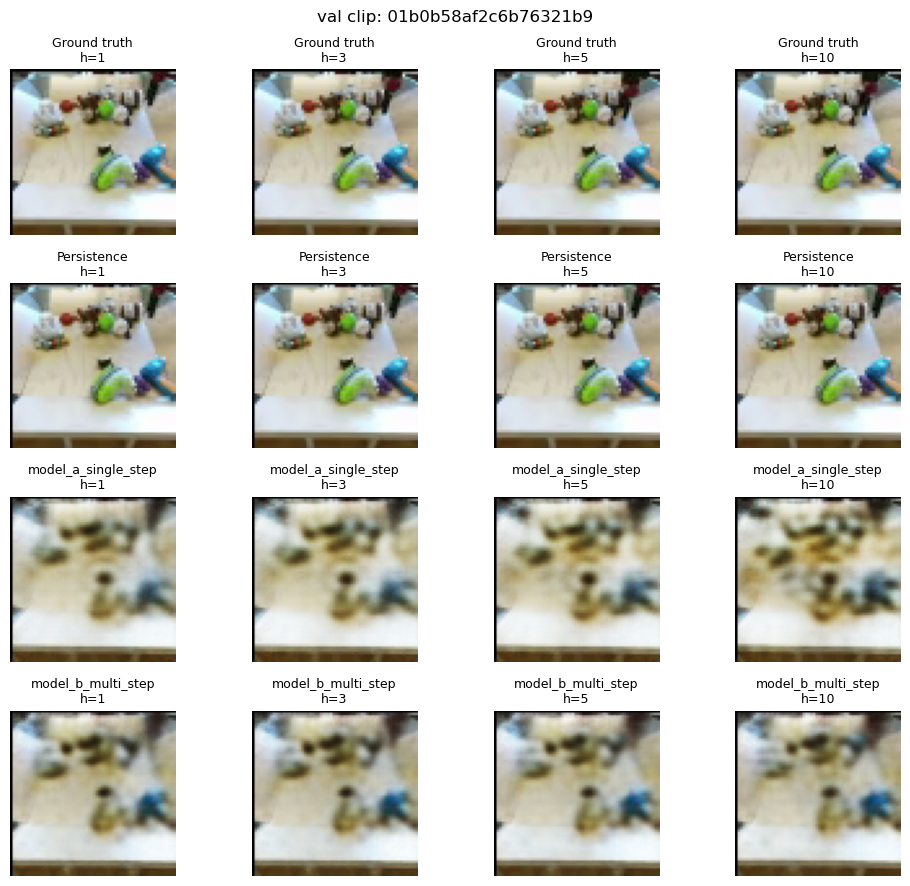

In [10]:
example = loader.dataset[0]
selected = [1, 3, 5, 10]
with torch.no_grad():
    context = example["context"][None].to(DEVICE)
    actions = example["actions"][None].to(DEVICE)
    visual = {"Ground truth": example["target"].numpy(),
              "Persistence": np.repeat(example["context"][-1:].numpy(), max(HORIZONS), axis=0)}
    for name, model in models.items():
        visual[name] = rollout(model, context, actions)[0].cpu().numpy()
fig, axes = plt.subplots(len(visual), len(selected), figsize=(10, 9), squeeze=False)
for r, (name, frames) in enumerate(visual.items()):
    for c, h in enumerate(selected):
        axes[r, c].imshow(frames[h-1].transpose(1, 2, 0).clip(0, 1))
        axes[r, c].set_title(f"{name}\nh={h}", fontsize=9)
        axes[r, c].axis("off")
fig.suptitle(f"{SPLIT} clip: {example['clip_id']}")
plt.tight_layout()
plt.savefig(EVAL_DIR / "prediction_grid.png", dpi=160, bbox_inches="tight")
plt.show()

## First report draft — measured test results

## Abstract

We compared persistence, a single-step convolutional model (Model A), and the same architecture trained on five-step self-fed rollouts (Model B). Using 900 training clips, 100 validation clips, and 256 held-out test clips, Model B reduced horizon-5 MSE by 48.65% relative to persistence and horizon-10 MSE by 45.46% relative to Model A. Both exceeded the proposal's 10% improvement targets in this experiment. Persistence retained higher full-frame SSIM and lower one-step MSE, so the learned model did not dominate every metric. Results apply to one seed and a community-reencoded subset of BAIR.

## Research question

Does training an action-conditioned model on its own multi-step predictions reduce error accumulation compared with training the same architecture only on real one-step inputs? We hypothesized that Model B would improve longer-horizon pixel accuracy. The predefined goals were at least 10% lower MSE than persistence at horizon 5 and at least 10% lower MSE than Model A at horizon 10.

## Data and preprocessing

We used auxiliary-camera videos and paired robot commands from `guyuchao/BAIR`, revision `776ad3b`. The converter streamed 1,000 training clips and 256 original test clips from shards 0 and 4 into Parquet. The training subset was selected in source order, then split into 900 training and 100 validation clips using seed 4620. The community index named `bair_val.json` refers to original test-directory clips; these were preserved as our test set.

Each clip contains 30 RGB frames at 64×64 resolution and four action dimensions. Images were scaled to [0,1], and action standardization used training clips only. Clips were split before creating windows. MP4 decoding may differ from the original raw pixels, so these results should not be presented as a directly comparable full-release BAIR benchmark. The implementation assumes action[t] corresponds to the transition from frame[t] to frame[t+1]; that physical timing convention has not been independently verified against the original collection logs.

## Models and training

The encoder receives three consecutive RGB frames as nine channels and compresses them to an 8×8 feature map. A learned action embedding is broadcast spatially and fused with visual features. A convolutional decoder predicts the next RGB image. Recursive predictions replace the oldest frame in the three-frame context.

Persistence repeats the last observed frame at every horizon. Model A minimizes one-step pixel MSE. Model B minimizes mean pixel MSE over five self-fed steps with gradients through the entire rollout. Both share the same architecture, initial parameters, eligible window population, and seeded window order. Future commands are provided during rollouts; the system predicts video conditional on actions rather than choosing actions.

Both models trained for 10 epochs with Adam, learning rate 0.001, batch size 32, width 32, and gradient clipping at 1.0. Training used PyTorch 2.9.1 on the Mac's MPS device. Model A took 22.6 minutes and Model B 35.2 minutes. Checkpoints were selected by validation endpoint MSE at horizon 10: epoch 2 for Model A and epoch 8 for Model B. Model B's greater computational cost should be considered when interpreting its advantage.

## Evaluation

Each held-out clip contributes one fixed window starting at frame 0, with three observed context frames and ten future targets. Learned models receive no future observed images. We average endpoint MSE, per-clip PSNR, and RGB SSIM across clips at each horizon. SSIM uses a 7×7 uniform window and data range 1. Motion MSE includes pixels whose mean absolute RGB change between consecutive true frames exceeds 10/255. Empty motion masks are excluded: horizon 5 has 254 clips with motion, while horizons 1 and 10 have 256.

The paired bootstrap resamples whole clips 2,000 times. Its intervals describe uncertainty across these test clips conditional on this training run; they do not measure variation across seeds.

## Test results

| Model | Horizon | MSE ↓ | PSNR (dB) ↑ | SSIM ↑ | Motion MSE ↓ |
|---|---:|---:|---:|---:|---:|
| Persistence | 1 | 0.003894 | 27.64 | 0.946 | 0.042706 |
| Model A: single-step | 1 | 0.007785 | 21.40 | 0.799 | 0.032892 |
| Model B: multi-step | 1 | 0.007661 | 21.48 | 0.805 | 0.033956 |
| Persistence | 5 | 0.020114 | 18.41 | 0.822 | 0.104706 |
| Model A: single-step | 5 | 0.016419 | 18.10 | 0.648 | 0.055389 |
| Model B: multi-step | 5 | 0.010330 | 20.15 | 0.756 | 0.044339 |
| Persistence | 10 | 0.025239 | 17.31 | 0.782 | 0.090266 |
| Model A: single-step | 10 | 0.025351 | 16.18 | 0.538 | 0.058243 |
| Model B: multi-step | 10 | 0.013825 | 18.85 | 0.692 | 0.040636 |

The proposal's comparisons were:

* Model A: single-step versus Persistence at horizon 5: **18.37% lower MSE**, paired bootstrap 95% interval [11.97%, 24.28%].
* Model B: multi-step versus Persistence at horizon 5: **48.65% lower MSE**, paired bootstrap 95% interval [44.39%, 52.67%].
* Model B: multi-step versus Model A: single-step at horizon 10: **45.46% lower MSE**, paired bootstrap 95% interval [43.78%, 47.08%].

Both predefined Model B targets were met, with their reported intervals above the 10% threshold. Model B's horizon-10 MSE was approximately 45.2% lower than persistence as well. The two learned models had similar one-step MSE, but Model A's error grew substantially more by horizon 10. This supports the multi-step training hypothesis for the tested subset and run.

Persistence was best on one-step full-frame MSE and had higher full-frame SSIM at all three reported horizons. Model A was slightly worse than persistence on horizon-10 MSE. Thus, single-step training alone did not reliably improve long-horizon accuracy. Model B had lower motion-region MSE than persistence at all reported horizons; this is useful evidence beyond a full-frame metric dominated by static background. It still does not establish physically accurate contacts or realistic object dynamics.

![Test metrics by prediction horizon](../artifacts/bair_hf_aux1_v1/run_20261117T163624_197610Z/evaluation_test/metrics_by_horizon.png)

![Predictions for the fixed first test clip](../artifacts/bair_hf_aux1_v1/run_20261117T163624_197610Z/evaluation_test/prediction_grid.png)

The prediction grid uses the first test clip by the fixed manifest order. It is an illustration rather than evidence that every clip behaves similarly. Full per-clip metrics and paired comparisons are saved in the run's `evaluation_test` directory.

## Limitations and ethical implications

This is a small source-order training subset, one seed, one camera, one collection setting, and ten epochs per model. It does not establish full-dataset performance, statistical reproducibility across retraining, or generalization to another robot. MP4 compression affects comparisons with raw-pixel benchmarks. The assumed action timing remains a data-verification limitation. A deterministic MSE objective can blur uncertain outcomes. Changing-pixel masks are not object segmentation, and improved image metrics do not establish safe physical planning.

The experiments use recorded videos and do not control a robot. Future use in planning would require separate checks for unfamiliar scenes, unreliable predictions, and collision risks. More convincing follow-up experiments would repeat training across seeds, test action-shuffling on validation data, and compare methods under matched compute budgets. These are follow-ups, not prerequisites for reporting this initial result.

## Conclusion

For this BAIR subset and training configuration, five-step self-fed training improved long-horizon pixel prediction and met both proposed MSE targets on the held-out test set. Persistence remained competitive on structural similarity and superior at the shortest horizon, limiting any claim of overall visual superiority.

## Sources and reproducibility

* Supplied project proposal: research question, three-system comparison, and 10% targets.
* [Community BAIR source](https://huggingface.co/datasets/guyuchao/BAIR/tree/776ad3b).
* [Official TFDS BAIR schema](https://www.tensorflow.org/datasets/catalog/bair_robot_pushing_small).
* Run: `run_20261117T163624_197610Z`; seed: 4620. Exact configuration, manifest fingerprint, training histories, checkpoints, and evaluation tables are preserved under `artifacts/bair_hf_aux1_v1/`.
